# 01 — Dataset overview & quality control

**Context.** This project reproduces Song, Qu, Blumm & Barabasi, *Limits of Predictability in Human Mobility* (Science 327, 2010) on the **GeoLife** GPS dataset (182 users, Beijing, 2007-2012), and extends it toward proactive route suggestion ("every Thursday 15:15 the user drives to music school"). The raw GPS traces were ingested into stop points (stay-point detection, Zheng et al. 2009), trips between stops, an hourly H3-res-8 location grid, per-user entropy/predictability estimates, statistical baselines, mined routine cards, and mobility graphs.

This notebook answers: *what did we actually collect, and can we trust it?* It covers the dataset overview, temporal coverage, the cohort-selection funnel, stop/trip distributions, and a single-day timeline for one user.

**Inputs (read-only):** `data/processed/coverage_stats.parquet`, `points.parquet`, `stops.parquet`, `trips.parquet`, `cohort.parquet`.
**Outputs:** `reports/01_*.png`.

In [1]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def _find_root():
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p / "data" / "processed").is_dir():
            return p
    raise RuntimeError("project root with data/processed not found")


ROOT = _find_root()
DATA = ROOT / "data" / "processed"
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

mpl.rcParams.update({
    "figure.figsize": (11, 4.2),
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

def save(fig, name):
    fig.savefig(REPORTS / name, dpi=150, bbox_inches="tight")
    print(f"saved reports/{name}")

WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]


## 1. Dataset overview

24.8M GPS points from 182 users. We read only the columns needed here — `points.parquet` is large, so full scans are avoided elsewhere in the pipeline.

In [2]:
cov = pd.read_parquet(DATA / "coverage_stats.parquet")
cohort = pd.read_parquet(DATA / "cohort.parquet")["user"].tolist()

pts = pd.read_parquet(DATA / "points.parquet", columns=["user", "ts", "lat", "lon"])

print(f"users           : {cov['user'].nunique()}")
print(f"points          : {len(pts):,}")
print(f"timespan        : {cov['first_ts'].min()}  ->  {cov['last_ts'].max()}")
print(f"active days     : median {cov['active_days'].median():.1f}, "
      f"mean {cov['active_days'].mean():.1f}, max {cov['active_days'].max()}")
n_pre = int((pts["ts"] < pd.Timestamp("2007-01-01")).sum())
print(f"points pre-2007 : {n_pre:,} ({n_pre / len(pts):.3%}) — stale/bogus device clocks, excluded from plots")

users           : 182
points          : 24,824,210
timespan        : 2000-01-01 23:12:19  ->  2012-07-27 08:31:20
active days     : median 19.5, mean 61.2, max 1273


points pre-2007 : 3 (0.000%) — stale/bogus device clocks, excluded from plots


## 2. Temporal coverage

GeoLife logging is voluntary and bursty: users record intensively for weeks, then disappear. Coverage concentrates in **2008-2009** — the peak month is **April 2009** (1.76M points) — while 2010-2011 together contribute only 17.2% of points and 2012 is a thin tail. Note the log scale.

saved reports/01_points_per_month.png


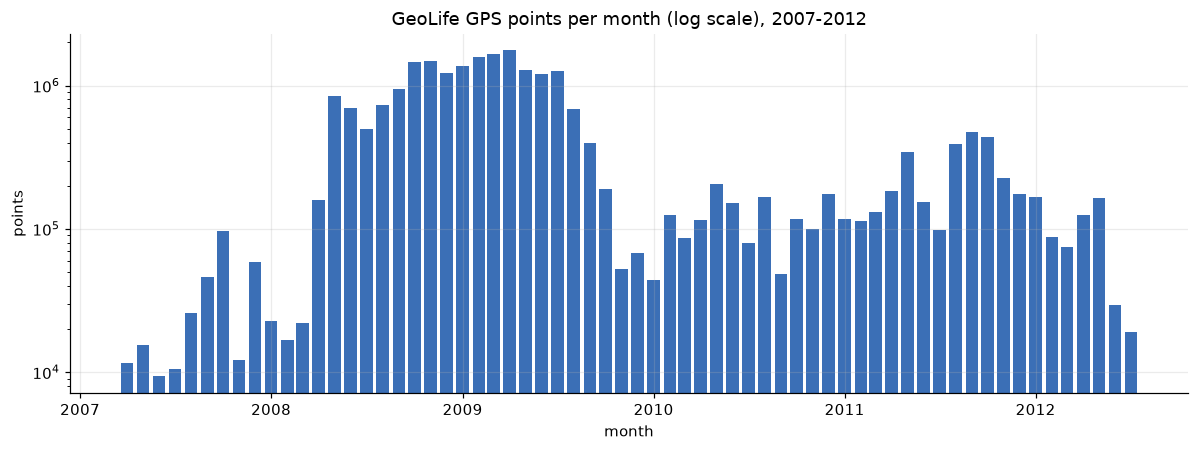

peak month : 2009-04 with 1,757,153 points
2010-2011 share of points: 17.2%


In [3]:
monthly = pts.loc[pts["ts"] >= "2007-01-01"].groupby(pts["ts"].dt.to_period("M")).size()

fig, ax = plt.subplots()
ax.bar(monthly.index.to_timestamp(), monthly.values, width=24, color="#3b6fb6")
ax.set_yscale("log")
ax.set_title("GeoLife GPS points per month (log scale), 2007-2012")
ax.set_xlabel("month")
ax.set_ylabel("points")
fig.tight_layout()
save(fig, "01_points_per_month.png")
plt.show()

print(f"peak month : {monthly.idxmax()} with {monthly.max():,} points")
print(f"2010-2011 share of points: "
      f"{monthly.loc['2010-01':'2011-12'].sum() / monthly.sum():.1%}")

## 3. Active days per user & the cohort funnel

The Song et al. analysis needs users with enough history. Our funnel:

1. **182** users in GeoLife
2. **179** users with at least one detected stop
3. **76** users with >= 30 active days **and** >= 5 distinct H3-res-8 cells -> the **analysis cohort**

The 30-day / 5-cell cut is deliberately stricter than the paper's (>2 locations, >= 0.5 calls/hour over 3 months): GeoLife users are far sparser than phone-cell users, so we keep the funnel explicit rather than implicit.

saved reports/01_active_days.png


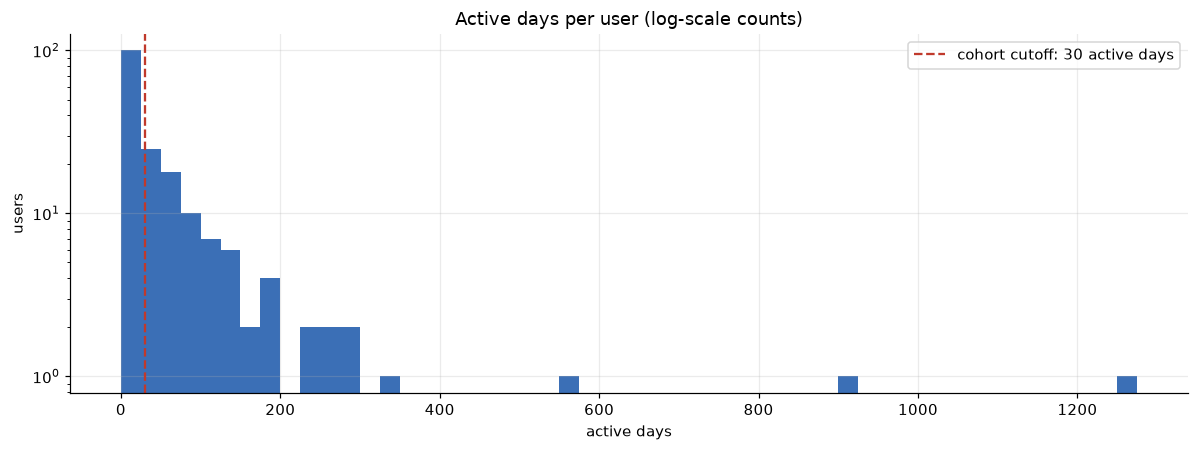

funnel: 182 users -> 179 with >=1 stop -> 76 in cohort
active days: cohort median 76 vs overall median 20


In [4]:
fig, ax = plt.subplots()
ax.hist(cov["active_days"], bins=np.arange(0, 1300, 25), color="#3b6fb6")
ax.axvline(30, color="#c0392b", lw=1.5, ls="--", label="cohort cutoff: 30 active days")
ax.set_yscale("log")
ax.set_title("Active days per user (log-scale counts)")
ax.set_xlabel("active days")
ax.set_ylabel("users")
ax.legend()
fig.tight_layout()
save(fig, "01_active_days.png")
plt.show()

n_all = cov["user"].nunique()
n_stops_users = int((cov["n_stops"] > 0).sum())
mask = (cov["active_days"] >= 30) & (cov["n_r8"] >= 5)
n_cohort = int(mask.sum())
print(f"funnel: {n_all} users -> {n_stops_users} with >=1 stop -> {n_cohort} in cohort")
print(f"active days: cohort median {cov.loc[mask, 'active_days'].median():.0f} "
      f"vs overall median {cov['active_days'].median():.0f}")
assert set(cov.loc[mask, "user"]) == set(cohort), "cohort.parquet disagrees with the funnel" 

## 4. Stops and trips

Stops = stay points (consecutive points within a small radius for >= 10 min). Trips = movements between consecutive stops. All three distributions are heavy-tailed, hence the log scales.

Known artifacts to keep in mind:
- **Dwell times** are capped by construction at ~41 h, but a handful of overnight/weekend stays reach it.
- **Trip distances** contain extreme outliers — the largest is an **11,129 km** displacement (user 163), i.e. someone flew home to another country with the logger on. Travel time up to ~4 years marks trips stitched across long device-off gaps; these are relocations/gaps, not movement.

In [5]:
stops = pd.read_parquet(DATA / "stops.parquet")
trips = pd.read_parquet(DATA / "trips.parquet")

print(f"stops: {len(stops):,}   trips: {len(trips):,}")
print("dwell_min   percentiles p10/p50/p90/p99:",
      [float(np.round(stops["dwell_min"].quantile(q), 1)) for q in (0.1, 0.5, 0.9, 0.99)])
print("trip dist_km percentiles p10/p50/p90/p99:",
      [float(np.round(trips["dist_km"].quantile(q), 2)) for q in (0.1, 0.5, 0.9, 0.99)])
print("trip travel_min percentiles p50/p90/p99:",
      [float(np.round(trips["travel_min"].quantile(q), 1)) for q in (0.5, 0.9, 0.99)])

i = trips["dist_km"].idxmax()
print("largest trip:", trips.loc[i, ["user", "travel_min", "dist_km"]].to_dict())

stops: 23,348   trips: 23,169
dwell_min   percentiles p10/p50/p90/p99: [10.0, 18.0, 61.0, 206.0]
trip dist_km percentiles p10/p50/p90/p99: [0.1, 1.2, 17.07, 895.22]
trip travel_min percentiles p50/p90/p99: [78.0, 2424.4, 20175.5]
largest trip: {'user': '163', 'travel_min': 3552.0, 'dist_km': 11129.016709959964}


saved reports/01_distributions.png


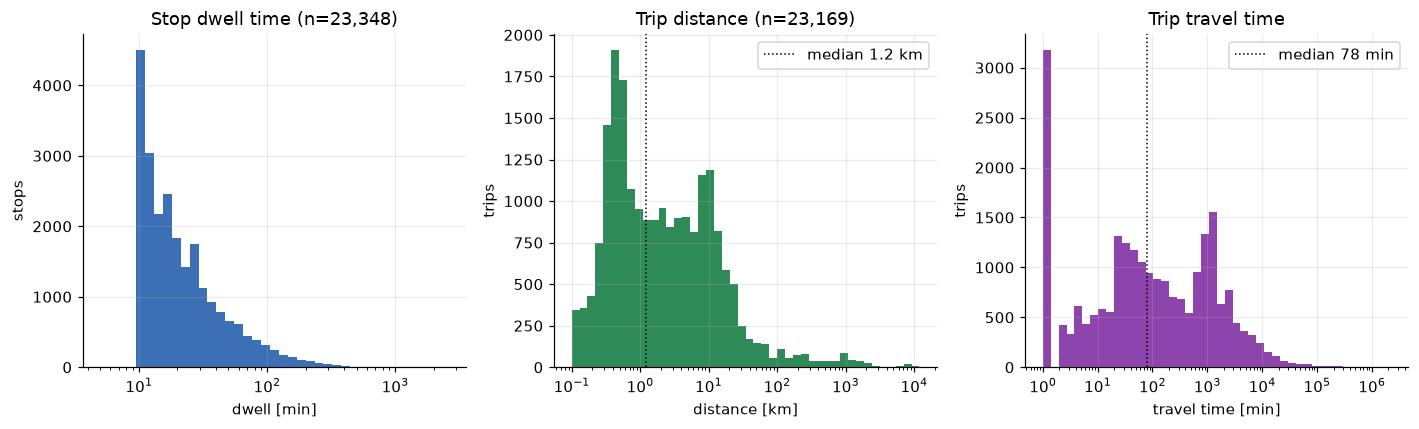

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

axes[0].hist(stops["dwell_min"], bins=np.logspace(0.7, np.log10(2600), 40), color="#3b6fb6")
axes[0].set_xscale("log")
axes[0].set_title(f"Stop dwell time (n={len(stops):,})")
axes[0].set_xlabel("dwell [min]")
axes[0].set_ylabel("stops")

axes[1].hist(trips["dist_km"], bins=np.logspace(-1, np.log10(12000), 45), color="#2e8b57")
axes[1].set_xscale("log")
axes[1].set_title(f"Trip distance (n={len(trips):,})")
axes[1].set_xlabel("distance [km]")
axes[1].set_ylabel("trips")
axes[1].axvline(1.2, color="k", lw=1, ls=":", label="median 1.2 km")
axes[1].legend()

axes[2].hist(trips["travel_min"], bins=np.logspace(0, np.log10(2.2e6), 45), color="#8e44ad")
axes[2].set_xscale("log")
axes[2].set_title("Trip travel time")
axes[2].set_xlabel("travel time [min]")
axes[2].set_ylabel("trips")
axes[2].axvline(78, color="k", lw=1, ls=":", label="median 78 min")
axes[2].legend()

fig.tight_layout()
save(fig, "01_distributions.png")
plt.show()

## 5. One user, one day

User **128** is the second-largest cohort user by point count (1.2M points, 908 active days) — a good sanity-check subject. We plot the single richest day: longitude vs latitude coloured by local hour, the raw material that stop detection and the hourly H3 grid summarise.

saved reports/01_user128_day.png


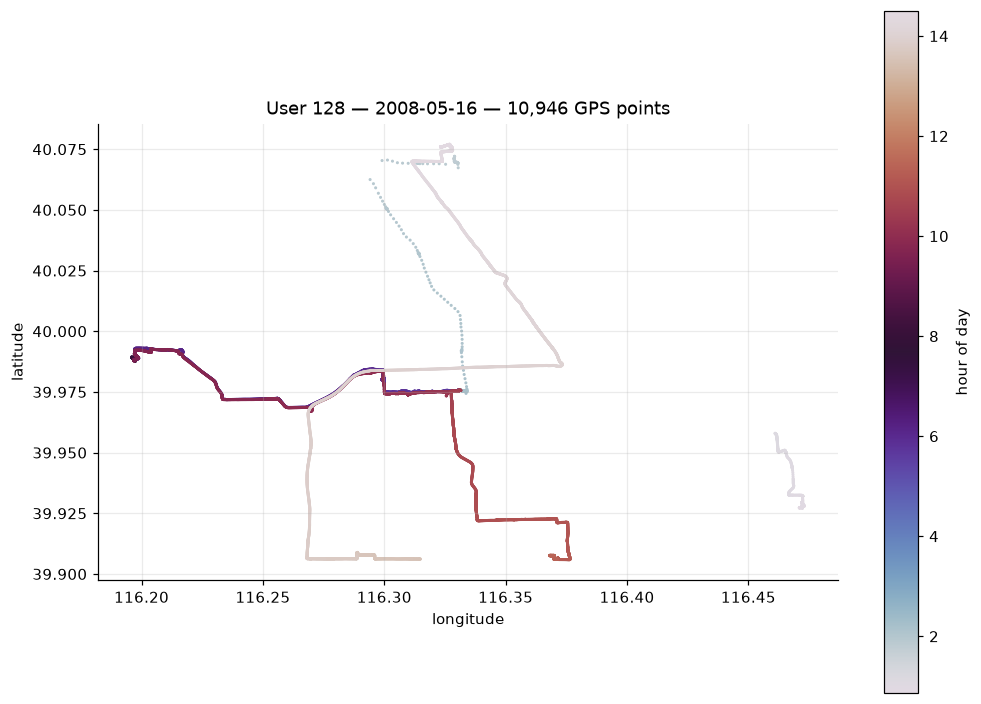

day span: 2008-05-16 00:52:13 -> 2008-05-16 14:30:31  (116.196..116.473 lon, 39.906..40.077 lat)


In [7]:
u = pts[pts["user"] == "128"]
day = u["ts"].dt.date.value_counts().idxmax()
d = u[u["ts"].dt.date == day].sort_values("ts").copy()
hourfrac = d["ts"].dt.hour + d["ts"].dt.minute / 60

fig, ax = plt.subplots(figsize=(9.5, 6.5))
sc = ax.scatter(d["lon"], d["lat"], c=hourfrac, s=4, cmap="twilight", linewidths=0)
fig.colorbar(sc, ax=ax, label="hour of day")
ax.set_title(f"User 128 — {day} — {len(d):,} GPS points")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_aspect("equal")
fig.tight_layout()
save(fig, "01_user128_day.png")
plt.show()

print(f"day span: {d['ts'].min()} -> {d['ts'].max()}  "
      f"({d['lon'].min():.3f}..{d['lon'].max():.3f} lon, {d['lat'].min():.3f}..{d['lat'].max():.3f} lat)")

## Takeaways & caveats

- 182 users / 24.8M points / 2007-2012, but **sparse and bursty**: median user has only ~20 active days; the 76-user cohort (>= 30 active days, >= 5 res-8 cells) is the honest analysis base.
- Only 3 points (0.000%) carry pre-2007 timestamps (stale device clocks) — negligible, but the reason the coverage table starts in 2000; they are excluded from the monthly plot.
- Stop dwell (median 18 min) and trip distance (median 1.2 km) are heavily right-tailed; extreme trips (max **11,129 km**, travel times up to years) are relocations or device-off gaps, not mobility — downstream analyses use medians/quantiles and per-user normalisation.
- The single-day track shows exactly the kind of home/commute structure that makes hourly prediction plausible — but only on days when the logger was on.